# Chương 2 bài 1 Trực quan hóa rượu đỏ

**Nguồn:** Lab EDA, mục bài tập thực hành 1 phần 1.2, trang 8

**Đề bài:** Thực hiện trực quan hóa dữ liệu phân loại chất lượng rượu đỏ.

Code triển khai bài tập theo dữ liệu đã cung cấp; không phải đoạn chép nguyên văn bài mẫu.

In [1]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data').is_dir() and (p / 'README.md').is_file())
DATA = ROOT / 'data'
OUT = ROOT / 'ket_qua' / 'C2_BT01_TrucQuan_RuouDo'
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'figure.figsize': (8, 4)})

def save_fig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140, bbox_inches='tight')
    plt.show()

def save_summary(values):
    (OUT / 'tom_tat.json').write_text(
        json.dumps(values, ensure_ascii=False, indent=2), encoding='utf-8'
    )


## 1 Nạp dữ liệu

In [2]:
df = pd.read_csv(DATA / 'winequality-red.csv', sep=None, engine='python')
print(df.shape)
print(df.head())

(1599, 12)
   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.4              0.70         0.00  ...       0.56      9.4        5
1            7.8              0.88         0.00  ...       0.68      9.8        5
2            7.8              0.76         0.04  ...       0.65      9.8        5
3           11.2              0.28         0.56  ...       0.58      9.8        6
4            7.4              0.70         0.00  ...       0.56      9.4        5

[5 rows x 12 columns]


## 2 Phân tích đơn biến và hai biến

quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


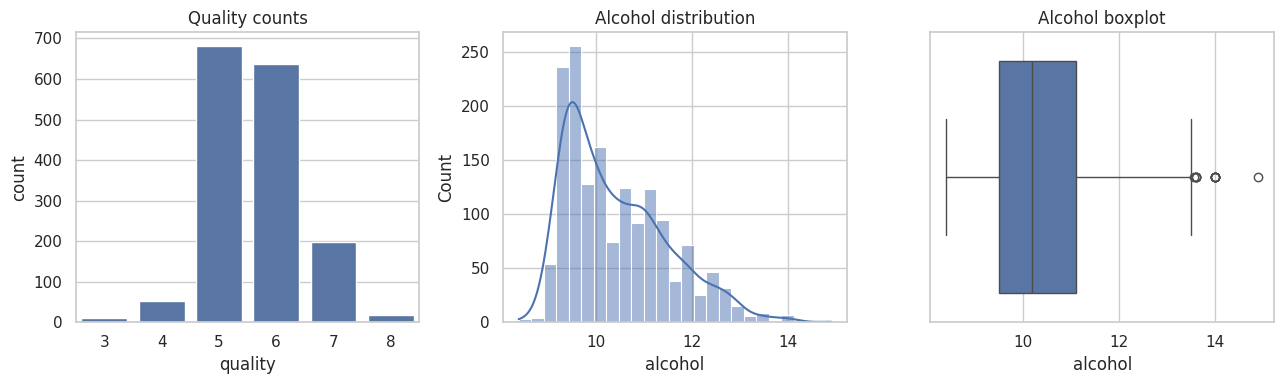

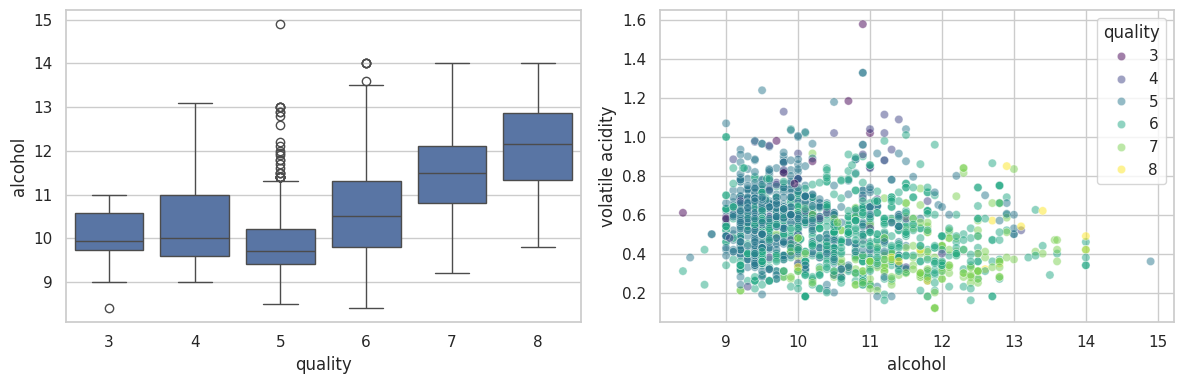

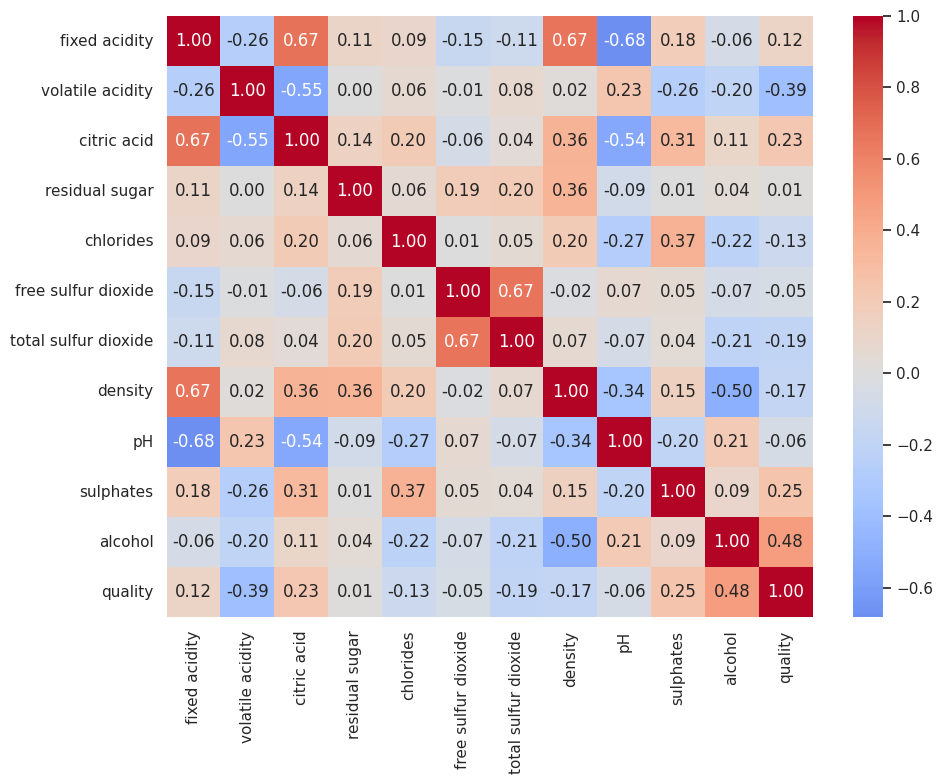

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
sns.countplot(data=df, x='quality', ax=axes[0])
sns.histplot(data=df, x='alcohol', bins=25, kde=True, ax=axes[1])
sns.boxplot(data=df, x='alcohol', ax=axes[2])
axes[0].set_title('Quality counts')
axes[1].set_title('Alcohol distribution')
axes[2].set_title('Alcohol boxplot')
save_fig('01_don_bien.png')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='quality', y='alcohol', ax=axes[0])
sns.scatterplot(data=df, x='alcohol', y='volatile acidity', hue='quality',
                palette='viridis', alpha=0.5, ax=axes[1])
save_fig('02_hai_bien.png')
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
save_fig('03_tuong_quan.png')
print(corr['quality'].sort_values(ascending=False))
save_summary({'rows':len(df), 'corr_alcohol_quality':float(corr.loc['alcohol','quality']),
              'corr_volatile_quality':float(corr.loc['volatile acidity','quality'])})

## Nhận xét và giới hạn
Histogram và boxplot mô tả một biến số; countplot mô tả nhãn; boxplot theo quality và scatter thể hiện quan hệ giữa hai biến. Heatmap tóm tắt tương quan tuyến tính nhiều cặp biến. Tương quan không chứng minh quan hệ nhân quả.